# Mansi Devganiya
# Track: Data Analytics
# Task: Level 1 - Sentiment Analysis

**Oasis Infobyte | SIP**

## Objective
To build machine learning models that classify the sentiment of airline tweets as positive, negative or neutral, and to compare their performance.

**Dataset:** Twitter US Airline Sentiment (Kaggle), 14,640 tweets
**Tools:** Python, pandas, NLTK, scikit-learn, matplotlib, seaborn, WordCloud

In [1]:
%pip install nltk wordcloud

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------------------------ --------------- 1.0/1.7 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 4.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,classification_report, confusion_matrix, ConfusionMatrixDisplay)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 200)

## 1. Data Loading and Inspection
The dataset has 15 columns, but only the tweet text and its sentiment label are needed.

In [3]:
df = pd.read_csv("Tweets.csv")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df = df[["text", "airline_sentiment"]]       # only the tweet and its sentiment label are needed
print("\nNull values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate tweet texts:", df["text"].duplicated().sum())
df.head()

Shape: (14640, 15)
Columns: ['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']

Null values:
 text                 0
airline_sentiment    0
dtype: int64

Duplicate rows: 188
Duplicate tweet texts: 213


,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials to the experience... tacky.,positive
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,neutral
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",negative
4,@VirginAmerica and it's a really big bad thing about it,negative


**Observations:**
- The dataset has 14,640 tweets and 15 columns. The two columns used are `text` (the tweet) and `airline_sentiment` (the label).
- There are no missing values in these two columns.
- There are 188 fully duplicate rows and 213 duplicate tweet texts. Duplicates must be removed, otherwise the same tweet could appear in both the training and the test set and make the results look better than they are.

## 2. Class Distribution
How many tweets belong to each sentiment class.

                   Tweets  Percent
airline_sentiment                 
negative             9178     62.7
neutral              3099     21.2
positive             2363     16.1


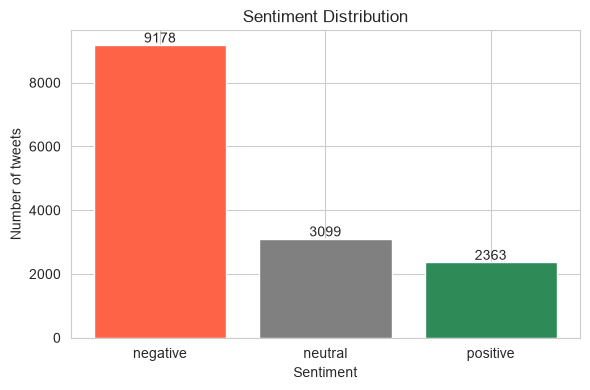

In [4]:
counts = df["airline_sentiment"].value_counts()
percent = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"Tweets": counts, "Percent": percent}))

order = ["negative", "neutral", "positive"]
plt.figure(figsize=(6, 4))
plt.bar(order, [counts[l] for l in order], color=["tomato", "gray", "seagreen"])
for i, label in enumerate(order):
    plt.text(i, counts[label] + 80, str(counts[label]), ha="center")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of tweets")
plt.tight_layout()
plt.show()

**Observations:**
- The classes are imbalanced: negative tweets are 9,178 (62.7%), neutral 3,099 (21.2%) and positive 2,363 (16.1%).
- A model that always predicts "negative" would already be 62.7% accurate, so accuracy alone is not a reliable measure here. Macro-averaged precision, recall and F1 (which give every class equal weight) are reported as well.

## 3. Text Preprocessing
Steps applied to every tweet:
1. Remove duplicate tweets.
2. Convert to lowercase.
3. Remove links, @mentions (airline names), the # sign, numbers, punctuation and HTML codes.
4. Tokenisation (split into words).
5. Remove stopwords (common words such as "the" and "is"). **Negation words such as "not" and "no" are kept**, because removing them would flip the meaning of a sentence.
6. Lemmatization (for example "delayed" becomes "delay"), so that different forms of a word are counted together. Lemmatization is preferred over stemming because it produces real words.

In [5]:
before = len(df)
df = df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
print("Duplicate tweets removed:", before - len(df))
print("Tweets remaining:", len(df))

Duplicate tweets removed: 213
Tweets remaining: 14427


In [6]:
# Keep negation words: removing "not" or "no" would flip the meaning of a sentence
negations = {"no", "nor", "not", "don", "don't", "didn't", "doesn't", "isn't", "wasn't", "aren't",
             "couldn't", "shouldn't", "wouldn't", "won't", "hasn't", "haven't", "hadn't", "weren't",
             "ain", "aren", "couldn", "didn", "doesn", "hadn", "hasn", "haven", "isn", "shouldn",
             "wasn", "weren", "won", "wouldn"}
stop_words = set(stopwords.words("english")) - negations
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()                                   # 1. lowercase
    text = text.replace("&amp;", " ")                     #    HTML code for "&" found in tweets
    text = re.sub(r"http\S+|www\.\S+", " ", text)         # 2. remove links
    text = re.sub(r"@\w+", " ", text)                     # 3. remove @mentions (airline names)
    text = text.replace("#", " ").replace("'", "")        # 4. drop the # sign and apostrophes
    text = re.sub(r"[^a-z\s]", " ", text)                 # 5. remove punctuation, numbers, emojis
    tokens = text.split()                                 # 6. tokenisation
    tokens = [lemmatizer.lemmatize(w) for w in tokens     # 7. stopword removal + lemmatization
              if w not in stop_words and len(w) > 1]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)

sample = df.sample(4, random_state=1)
for _, row in sample.iterrows():
    print("BEFORE:", row["text"])
    print("AFTER :", row["clean_text"], "\n")

BEFORE: @SouthwestAir No like I said I could not reach anyone at your company so I had to rent a car and chalk the whole thing up to a loss
AFTER : no like said could not reach anyone company rent car chalk whole thing loss 

BEFORE: @united Male agnt in LAS threatens Canadian cust when cust takes pic of him at gate after agents announce can't help rebook. #friendlyskies?
AFTER : male agnt la threatens canadian cust cust take pic gate agent announce cant help rebook friendlyskies 

BEFORE: @USAirways  I just reserved a flight with my companion certificate, where do I mail the certificate for verification???? THX!!!
AFTER : reserved flight companion certificate mail certificate verification thx 

BEFORE: @JetBlue NOT A HAPPY CUSTOMER. We've waited patiently, not to mention $150 and six months of marathon training, we need 2 be there tmrw.
AFTER : not happy customer weve waited patiently not mention six month marathon training need tmrw 



In [7]:
empty = (df["clean_text"].str.strip() == "").sum()
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)
print("Tweets that became empty after cleaning (removed):", empty)
print("Tweets remaining:", len(df))
print(df["airline_sentiment"].value_counts().to_dict())

Tweets that became empty after cleaning (removed): 19
Tweets remaining: 14408
{'negative': 9076, 'neutral': 3045, 'positive': 2287}


**Observations:**
- 213 duplicate tweets were removed, leaving 14,427.
- 19 tweets became empty after cleaning (for example, tweets that contained only a mention or an emoji) and were removed, leaving 14,408 tweets: 9,076 negative, 3,045 neutral and 2,287 positive.
- The before and after examples show that links, mentions and punctuation are gone, while negations such as "not" are kept.

## 4. Word Clouds
The most frequent words in each sentiment class (bigger word = more frequent).

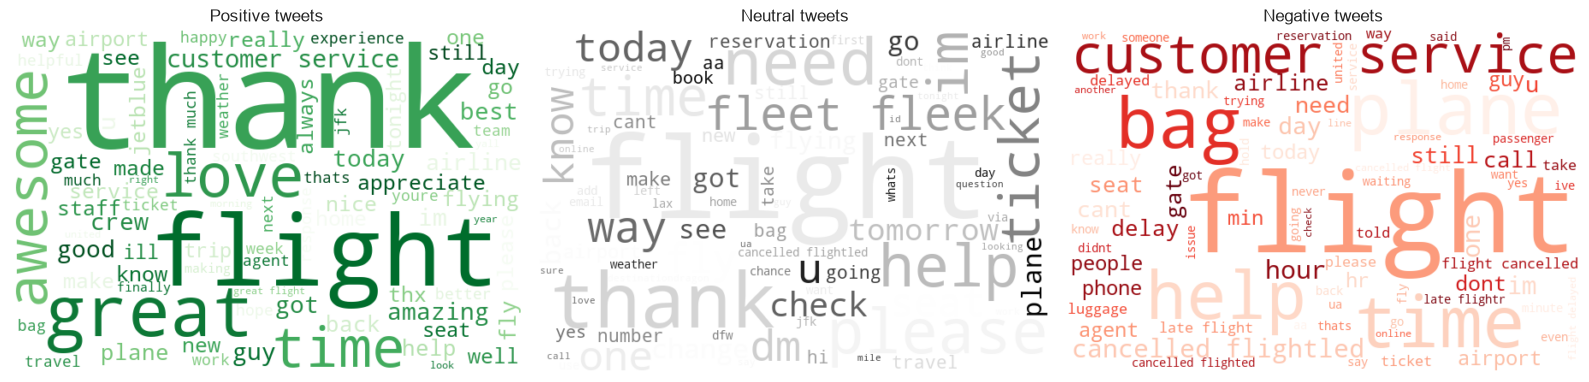

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, label, color in zip(ax, ["positive", "neutral", "negative"], ["Greens", "Greys", "Reds"]):
    words = " ".join(df.loc[df["airline_sentiment"] == label, "clean_text"])
    wc = WordCloud(width=600, height=400, background_color="white", colormap=color, max_words=80).generate(words)
    a.imshow(wc, interpolation="bilinear")
    a.set_title(f"{label.capitalize()} tweets")
    a.axis("off")
plt.tight_layout()
plt.show()

**Observations:**
- **Positive tweets** are dominated by appreciation words such as "thank", "great", "awesome" and "love".
- **Negative tweets** contain words about service problems such as "delayed", "cancelled", "bag", "hold" and "customer service".
- **Neutral tweets** contain requests and questions, such as "help", "please", "need" and "ticket".
- Words such as "flight" appear in all three classes, so they do not help to separate them. This is exactly what TF-IDF handles in the next step.

## 5. Train/Test Split and TF-IDF Features
**Train/test split:** 80% of the tweets are used for training and 20% for testing. The split is stratified, so each set keeps the same share of negative, neutral and positive tweets.

**What TF-IDF measures:** TF-IDF (Term Frequency - Inverse Document Frequency) gives each word a weight in each tweet. A word gets a high weight if it appears often in that tweet but is rare in the other tweets, so it is a good clue about that tweet. Very common words such as "flight" get a low weight. Single words and word pairs (1 to 2 words) are used, and words that appear in fewer than 2 tweets are ignored.

The vectorizer is fitted on the training data only, so no information from the test set leaks into the model.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["airline_sentiment"],
    test_size=0.2, random_state=42, stratify=df["airline_sentiment"])

print("Training tweets:", len(X_train), "| Test tweets:", len(X_test))

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000)
X_train_tfidf = tfidf.fit_transform(X_train)       # learn the vocabulary on training data only
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF matrix shape (train):", X_train_tfidf.shape)

Training tweets: 11526 | Test tweets: 2882
TF-IDF matrix shape (train): (11526, 13919)


## 6. Model Training and Evaluation
Three classifiers are trained and compared:
- **Multinomial Naive Bayes:** the standard baseline for text classification.
- **Logistic Regression:** a linear model that gives a probability for each class.
- **Linear SVM:** a linear model that separates the classes with the widest possible margin.

Because the classes are imbalanced, Logistic Regression and Linear SVM use `class_weight="balanced"`, which gives more importance to the smaller classes. Naive Bayes does not support this option.

In [10]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=42)
}

predictions, rows = {}, []
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    predictions[name] = pred
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro")
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f})

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Naive Bayes,0.710,0.788,0.489,0.518
Logistic Regression,0.775,0.716,0.741,0.727
Linear SVM,0.776,0.715,0.702,0.708


In [11]:
for name, pred in predictions.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, pred, digits=3))

Naive Bayes
              precision    recall  f1-score   support

    negative      0.696     0.993     0.818      1815
     neutral      0.743     0.171     0.278       609
    positive      0.927     0.303     0.457       458

    accuracy                          0.710      2882
   macro avg      0.788     0.489     0.518      2882
weighted avg      0.742     0.710     0.647      2882

Logistic Regression
              precision    recall  f1-score   support

    negative      0.884     0.821     0.851      1815
     neutral      0.572     0.663     0.614       609
    positive      0.690     0.740     0.714       458

    accuracy                          0.775      2882
   macro avg      0.716     0.741     0.727      2882
weighted avg      0.788     0.775     0.780      2882

Linear SVM
              precision    recall  f1-score   support

    negative      0.850     0.873     0.862      1815
     neutral      0.587     0.567     0.576       609
    positive      0.709     0.66

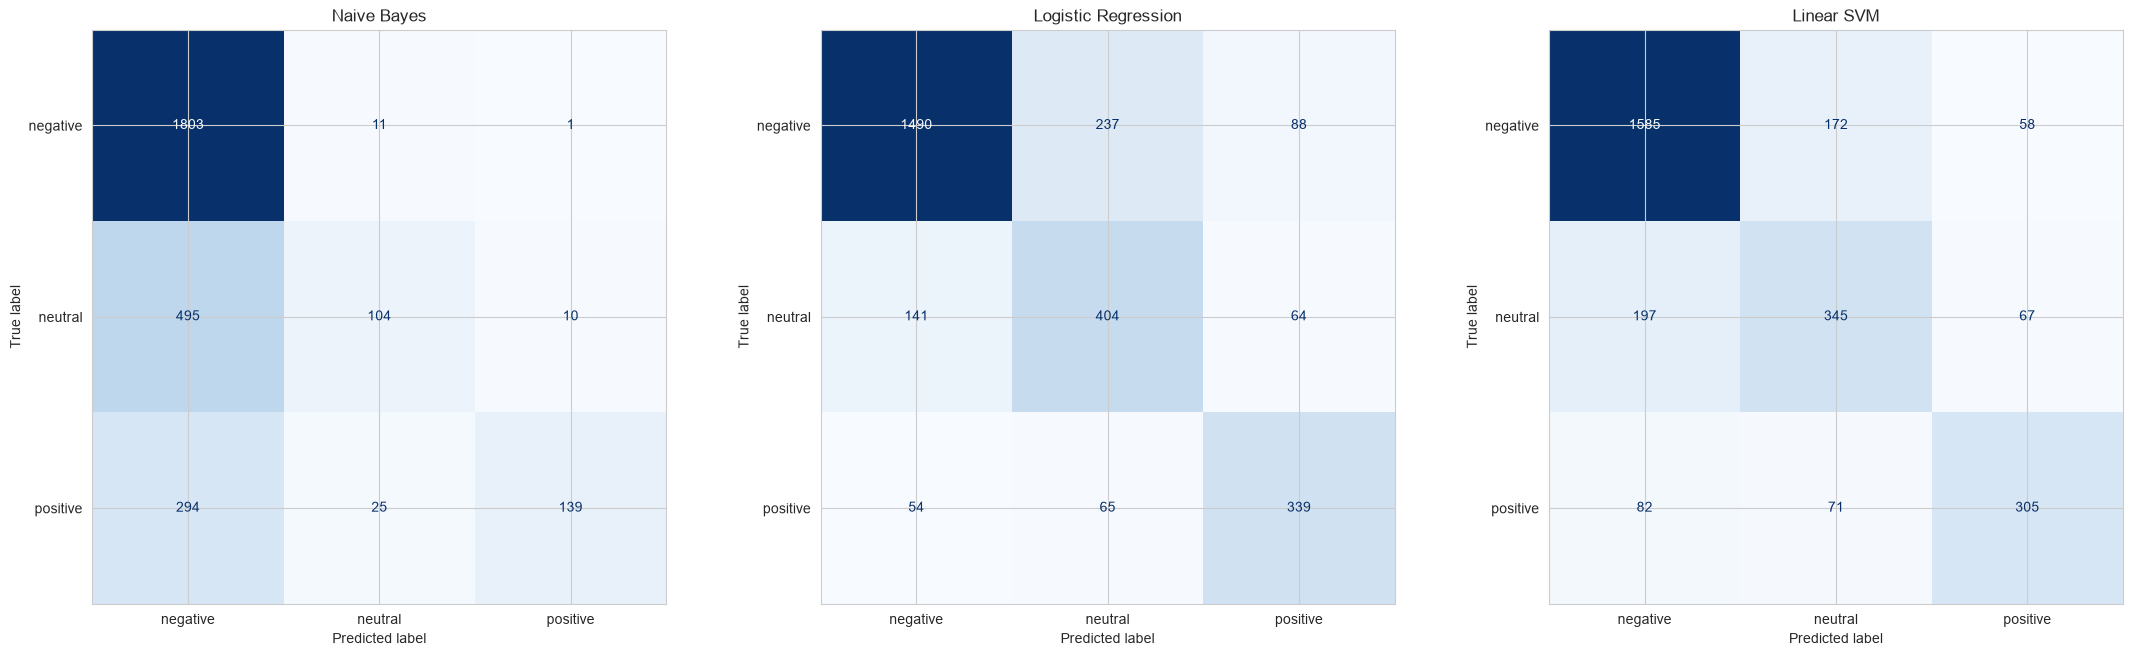

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(22, 6.6))
labels = ["negative", "neutral", "positive"]
for a, (name, pred) in zip(ax, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=a, cmap="Blues", colorbar=False, values_format="d")
    a.set_title(name)
plt.tight_layout()
plt.show()

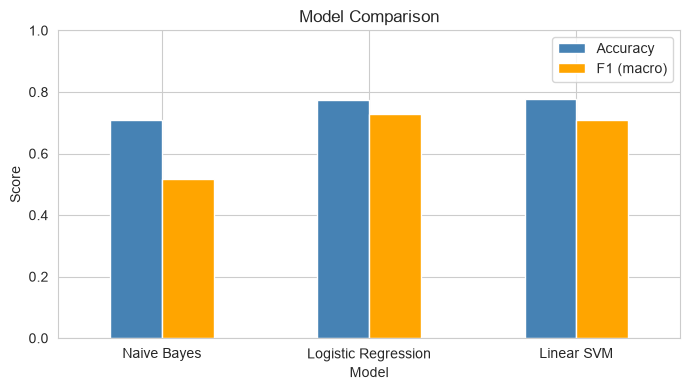

In [14]:
results[["Accuracy", "F1 (macro)"]].plot(kind="bar", figsize=(7, 4), color=["steelblue", "orange"])
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observations:**

| Model | Accuracy | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|
| Naive Bayes | 0.710 | 0.788 | 0.489 | 0.518 |
| Logistic Regression | 0.775 | 0.716 | 0.741 | **0.727** |
| Linear SVM | 0.776 | 0.715 | 0.702 | 0.708 |

- **Best model: Logistic Regression.** It has the highest macro F1 (0.727) and nearly the best accuracy (0.775). Linear SVM has almost the same accuracy (0.776), but a lower macro F1 (0.708).
- **Naive Bayes looks acceptable on accuracy (0.710) but is the weakest model.** It finds 99.3% of the negative tweets, but only 17.1% of the neutral and 30.3% of the positive tweets (recall). It leans heavily towards the majority class, which is why its macro F1 is only 0.518.
- **Logistic Regression is much more balanced:** recall is 82.1% for negative, 66.3% for neutral and 74.0% for positive tweets.
- **Neutral is the hardest class** for every model (F1 of 0.614 for Logistic Regression), because neutral tweets share words with both positive and negative tweets.

## 7. Most Important Words (Logistic Regression)
The words with the highest weights for each class show what the model learned.

In [15]:
best_name = results["F1 (macro)"].idxmax()
print("Best model (highest macro F1):", best_name)

best_model = models["Logistic Regression"]
feature_names = np.array(tfidf.get_feature_names_out())
for i, label in enumerate(best_model.classes_):
    top = feature_names[np.argsort(best_model.coef_[i])[-10:][::-1]]
    print(f"Top words for {label:8s}:", ", ".join(top))

Best model (highest macro F1): Logistic Regression
Top words for negative: hour, not, no, delayed, hr, worst, hold, bag, luggage, customer
Top words for neutral : hi, dm, avgeek, policy, possible, march, need, idea, delay cancelled, rate
Top words for positive: thanks, great, thank, love, awesome, best, amazing, thx, good, appreciate


**Observations:**
- **Negative:** "hour", "delayed", "worst", "hold", "bag", "luggage" and the negations "not" and "no". The model learned that delays, lost luggage and waiting are the main complaints. It also shows why keeping negations in the preprocessing was important.
- **Positive:** "thanks", "thank", "great", "love", "awesome", "best", "amazing" and "appreciate".
- **Neutral:** "hi", "dm", "policy", "possible" and "need", which are typical of questions and requests.

In [16]:
best_pred = predictions[best_name]
errors = X_test[best_pred != y_test.values].index

error_df = pd.DataFrame({
    "Tweet": df.loc[errors, "text"],
    "True": y_test.loc[errors],
    "Predicted": pd.Series(best_pred, index=y_test.index).loc[errors]
})
print("Total misclassified tweets:", len(error_df), "out of", len(y_test))
error_df.sample(5, random_state=42)

Total misclassified tweets: 649 out of 2882


,Tweet,True,Predicted
6167,@SouthwestAir @taylormdowns We share that value in common. :),positive,neutral
8941,"@USAirways Said only way to get on plane about to leave that would make my connection was a $75 fee. Instead of earlier, I am now Late Flightr!",negative,neutral
14176,@AmericanAir Rebooked for tomorrow morning. Never been here - not sure what I can see before tomorrow morning!,negative,neutral
2811,@united this is for a check-in luggage. Employee told me not to include wheels in the dimensions.,neutral,negative
6205,"@SouthwestAir I'm really craving your pretzels, please send me some.",positive,negative


**Observations:** the model misclassified 649 of 2,882 test tweets (22.5%). The errors fall into a few clear types:

1. *"We share that value in common. :)"* (true: positive, predicted: neutral). The tweet is friendly but has no strong positive word, and the smiley was removed during cleaning.
2. *"...a $75 fee... I am now Late Flightr!"* (true: negative, predicted: neutral). The complaint is expressed through facts (a fee, a delay) and not through negative words.
3. *"Rebooked for tomorrow morning. Never been here - not sure what I can see..."* (true: negative, predicted: neutral). The tweet sounds neutral, and the frustration is only implied by the situation.
4. *"...Employee told me not to include wheels in the dimensions."* (true: neutral, predicted: negative). The words "luggage" and "not" are strongly linked to negative tweets in the training data, so a neutral question is wrongly flagged as a complaint.
5. *"I'm really craving your pretzels, please send me some."* (true: positive, predicted: negative). The request pattern ("please send me") is common in complaints, and the tweet has no explicit positive word.

**Overall:** most errors involve neutral tweets, implied or indirect sentiment, and tweets with no strong keywords. A bag-of-words model cannot understand context, sarcasm or emojis.

## 9. Conclusion
**Best model:** Logistic Regression with TF-IDF features (accuracy 0.775, macro F1 0.727). It is more balanced across the three classes than Naive Bayes (macro F1 0.518) and slightly better than Linear SVM (macro F1 0.708).

**Real-world application:** an airline's customer-service team could use this model to scan tweets automatically and flag negative ones (precision 0.884, recall 0.821 for the negative class) so that unhappy customers get a quick reply. It could also track sentiment over time or by topic (delays, baggage, service) to find the biggest problems.

**Limitations:**
- Accuracy of about 77% means roughly 1 in 4 tweets is misclassified, mostly neutral and indirect ones.
- The classes are imbalanced (62.7% negative), and the data covers only airline tweets, so the model may not work well on other topics.
- Emojis and smileys were removed in cleaning, although they carry sentiment.

**Possible improvements:** keep emojis as features, add context-aware models such as transformers (BERT), and collect more neutral and positive examples.